In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/creditcard.csv")

print(df.shape)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/creditcard.csv'

In [2]:
import os
print(os.getcwd())
print(os.path.exists("data/raw/creditcard.csv"))
print(os.path.exists("../data/raw/creditcard.csv"))

C:\Users\POOVARASAN\Documents\ecommerce-risk-system
True
False


In [3]:
import pandas as pd

df = pd.read_csv("data/raw/creditcard.csv")

print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.info()
print("Missing values per column:")
print(df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [5]:
print("Duplicate rows:", df.duplicated().sum())

counts = df["Class"].value_counts()
print(counts)
print((df["Class"].value_counts(normalize=True) * 100).round(3))

Duplicate rows: 1081
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827
1     0.173
Name: proportion, dtype: float64


In [6]:
dup_mask = df.duplicated()

print("Duplicates by class:")
print(df[dup_mask]["Class"].value_counts())

print("\nAccuracy of always predicting 'legitimate':",
      round((df["Class"] == 0).mean(), 5))

df[df.duplicated(keep=False)].sort_values(["Time", "Amount"]).head(6)

Duplicates by class:
Class
0    1062
1      19
Name: count, dtype: int64

Accuracy of always predicting 'legitimate': 0.99827


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


In [7]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Rows before:", len(df))
print("Rows after: ", len(df_clean))
print("Duplicates left:", df_clean.duplicated().sum())
print(df_clean["Class"].value_counts())
print((df_clean["Class"].value_counts(normalize=True) * 100).round(4))

Rows before: 284807
Rows after:  283726
Duplicates left: 0
Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64


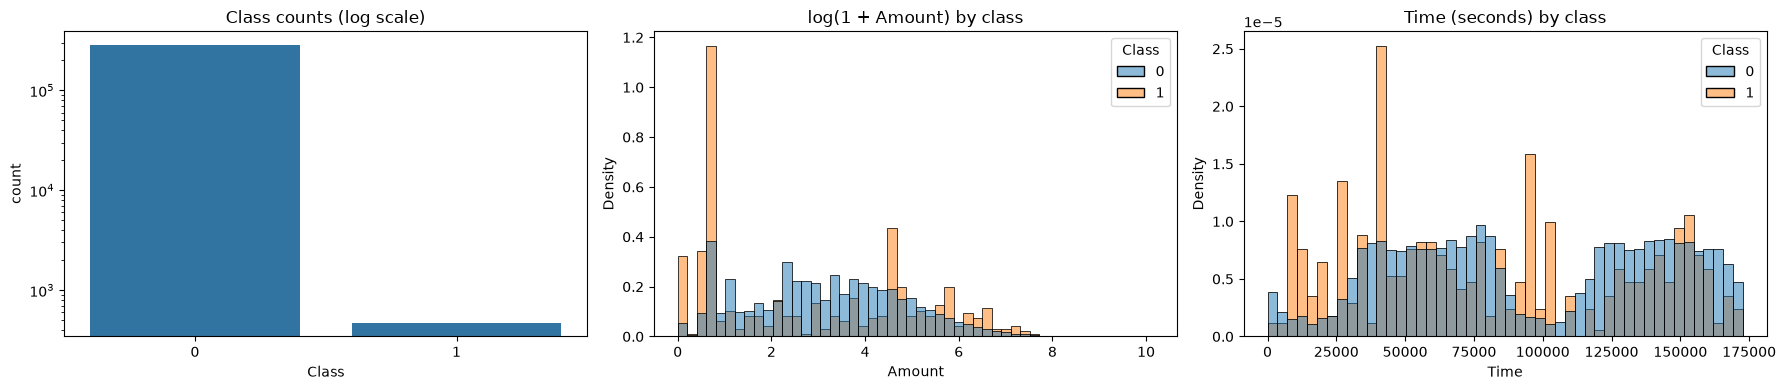

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Class balance (log scale so the tiny fraud bar is visible)
sns.countplot(data=df_clean, x="Class", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Class counts (log scale)")

# 2. Amount, log-transformed, split by class
sns.histplot(data=df_clean, x=np.log1p(df_clean["Amount"]), hue="Class",
             bins=50, stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("log(1 + Amount) by class")

# 3. Time by class
sns.histplot(data=df_clean, x="Time", hue="Class",
             bins=48, stat="density", common_norm=False, ax=axes[2])
axes[2].set_title("Time (seconds) by class")

plt.tight_layout()
plt.show()

print(df_clean.groupby("Class")["Amount"].describe().round(2))

In [9]:
df_clean = df_clean.sort_values("Time").reset_index(drop=True)
print("Time is sorted:", df_clean["Time"].is_monotonic_increasing)

n = len(df_clean)
train_end = int(n * 0.6)
val_end = int(n * 0.8)

train = df_clean.iloc[:train_end]
val = df_clean.iloc[train_end:val_end]
test = df_clean.iloc[val_end:]

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10} rows={len(part):6}  fraud={part['Class'].sum():4}  "
          f"({part['Class'].mean() * 100:.3f}%)  "
          f"Time {part['Time'].min():.0f} to {part['Time'].max():.0f}")

Time is sorted: True
train      rows=170235  fraud= 342  (0.201%)  Time 0 to 120392
validation rows= 56745  fraud=  57  (0.100%)  Time 120393 to 145233
test       rows= 56746  fraud=  74  (0.130%)  Time 145234 to 172792


In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, average_precision_score)

features = [f"V{i}" for i in range(1, 29)] + ["Amount"]

X_train, y_train = train[features], train["Class"]
X_val,   y_val   = val[features],   val["Class"]
X_test,  y_test  = test[features],  test["Class"]

baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
pred  = baseline.predict(X_val)
score = baseline.predict_proba(X_val)[:, 1]

print("Accuracy :", round(accuracy_score(y_val, pred), 5))
print("Recall   :", recall_score(y_val, pred))
print("Precision:", precision_score(y_val, pred, zero_division=0))
print("PR-AUC   :", round(average_precision_score(y_val, score), 5))

Accuracy : 0.999
Recall   : 0.0
Precision: 0.0
PR-AUC   : 0.001


In [2]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix)

v_cols = [f"V{i}" for i in range(1, 29)]

preprocess = ColumnTransformer([
    ("amount", Pipeline([("log", FunctionTransformer(np.log1p)),
                         ("scale", StandardScaler())]), ["Amount"]),
    ("v_feats", StandardScaler(), v_cols),
])

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

logreg.fit(X_train, y_train)

pred  = logreg.predict(X_val)
score = logreg.predict_proba(X_val)[:, 1]

print("Accuracy :", round(accuracy_score(y_val, pred), 5))
print("Precision:", round(precision_score(y_val, pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_val, pred), 3))
print("F1       :", round(f1_score(y_val, pred), 3))
print("PR-AUC   :", round(average_precision_score(y_val, score), 3))
print("ROC-AUC  :", round(roc_auc_score(y_val, score), 3))
print("Confusion matrix [[TN FP] [FN TP]]:")
print(confusion_matrix(y_val, pred))

NameError: name 'X_train' is not defined

In [3]:
import pandas as pd

df = pd.read_csv("data/raw/creditcard.csv")
df_clean = df.drop_duplicates().sort_values("Time").reset_index(drop=True)

n = len(df_clean)
train = df_clean.iloc[:int(n * 0.6)]
val   = df_clean.iloc[int(n * 0.6):int(n * 0.8)]
test  = df_clean.iloc[int(n * 0.8):]

features = [f"V{i}" for i in range(1, 29)] + ["Amount"]
X_train, y_train = train[features], train["Class"]
X_val,   y_val   = val[features],   val["Class"]
X_test,  y_test  = test[features],  test["Class"]

print(len(train), len(val), len(test))

170235 56745 56746


In [4]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix)

v_cols = [f"V{i}" for i in range(1, 29)]

preprocess = ColumnTransformer([
    ("amount", Pipeline([("log", FunctionTransformer(np.log1p)),
                         ("scale", StandardScaler())]), ["Amount"]),
    ("v_feats", StandardScaler(), v_cols),
])

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

logreg.fit(X_train, y_train)

pred  = logreg.predict(X_val)
score = logreg.predict_proba(X_val)[:, 1]

print("Accuracy :", round(accuracy_score(y_val, pred), 5))
print("Precision:", round(precision_score(y_val, pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_val, pred), 3))
print("F1       :", round(f1_score(y_val, pred), 3))
print("PR-AUC   :", round(average_precision_score(y_val, score), 3))
print("ROC-AUC  :", round(roc_auc_score(y_val, score), 3))
print("Confusion matrix [[TN FP] [FN TP]]:")
print(confusion_matrix(y_val, pred))

Accuracy : 0.99921
Precision: 0.643
Recall   : 0.474
F1       : 0.545
PR-AUC   : 0.624
ROC-AUC  : 0.968
Confusion matrix [[TN FP] [FN TP]]:
[[56673    15]
 [   30    27]]


In [5]:
from sklearn.base import clone

def evaluate(name, model):
    pred  = model.predict(X_val)
    score = model.predict_proba(X_val)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    return {
        "model": name,
        "precision": round(precision_score(y_val, pred, zero_division=0), 3),
        "recall": round(recall_score(y_val, pred), 3),
        "F1": round(f1_score(y_val, pred), 3),
        "PR-AUC": round(average_precision_score(y_val, score), 3),
        "ROC-AUC": round(roc_auc_score(y_val, score), 3),
        "TP": tp, "FP": fp, "FN": fn,
    }

logreg_w = Pipeline([
    ("prep", clone(preprocess)),
    ("model", LogisticRegression(max_iter=1000, random_state=42,
                                 class_weight="balanced")),
])
logreg_w.fit(X_train, y_train)

results = pd.DataFrame([
    evaluate("LogReg plain", logreg),
    evaluate("LogReg class_weight=balanced", logreg_w),
])
print(results.to_string(index=False))

                       model  precision  recall    F1  PR-AUC  ROC-AUC  TP   FP  FN
                LogReg plain      0.643   0.474 0.545   0.624    0.968  27   15  30
LogReg class_weight=balanced      0.024   0.895 0.047   0.753    0.969  51 2062   6


In [6]:
def at_thresholds(model, name, thresholds):
    score = model.predict_proba(X_val)[:, 1]
    rows = []
    for t in thresholds:
        pred = (score >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
        rows.append({
            "model": name, "threshold": t,
            "flagged": tp + fp,
            "TP": tp, "FP": fp, "FN": fn,
            "precision": round(tp / (tp + fp), 3) if (tp + fp) else 0.0,
            "recall": round(tp / (tp + fn), 3),
        })
    return pd.DataFrame(rows)

plain_t = at_thresholds(logreg, "plain", [0.05, 0.1, 0.2, 0.3, 0.5, 0.7])
weighted_t = at_thresholds(logreg_w, "weighted", [0.5, 0.8, 0.9, 0.95, 0.99, 0.999])

print(plain_t.to_string(index=False))
print()
print(weighted_t.to_string(index=False))

model  threshold  flagged  TP  FP  FN  precision  recall
plain       0.05       95  44  51  13      0.463   0.772
plain       0.10       70  42  28  15      0.600   0.737
plain       0.20       58  38  20  19      0.655   0.667
plain       0.30       51  32  19  25      0.627   0.561
plain       0.50       42  27  15  30      0.643   0.474
plain       0.70       23  19   4  38      0.826   0.333

   model  threshold  flagged  TP   FP  FN  precision  recall
weighted      0.500     2113  51 2062   6      0.024   0.895
weighted      0.800      610  49  561   8      0.080   0.860
weighted      0.900      335  48  287   9      0.143   0.842
weighted      0.950      216  46  170  11      0.213   0.807
weighted      0.990      112  44   68  13      0.393   0.772
weighted      0.999       80  44   36  13      0.550   0.772


In [7]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

logreg_smote = ImbPipeline([
    ("prep", clone(preprocess)),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
logreg_smote.fit(X_train, y_train)

def top_k(model, name, ks=(50, 100)):
    score = model.predict_proba(X_val)[:, 1]
    order = np.argsort(-score)
    y = y_val.values
    out = {"model": name,
           "PR-AUC": round(average_precision_score(y_val, score), 3)}
    for k in ks:
        caught = int(y[order[:k]].sum())
        out[f"caught@top{k}"] = caught
        out[f"recall@top{k}"] = round(caught / y.sum(), 3)
    return out

compare = pd.DataFrame([
    top_k(logreg, "LogReg plain"),
    top_k(logreg_w, "LogReg class_weight"),
    top_k(logreg_smote, "LogReg SMOTE"),
])
print(compare.to_string(index=False))

              model  PR-AUC  caught@top50  recall@top50  caught@top100  recall@top100
       LogReg plain   0.624            31         0.544             45          0.789
LogReg class_weight   0.753            38         0.667             44          0.772
       LogReg SMOTE   0.765            40         0.702             44          0.772


In [8]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)

compare = pd.DataFrame([
    top_k(logreg, "LogReg plain"),
    top_k(logreg_w, "LogReg class_weight"),
    top_k(rf, "RandomForest"),
])
print(compare.to_string(index=False))

              model  PR-AUC  caught@top50  recall@top50  caught@top100  recall@top100
       LogReg plain   0.624            31         0.544             45          0.789
LogReg class_weight   0.753            38         0.667             44          0.772
       RandomForest   0.758            43         0.754             44          0.772


In [9]:
df = pd.read_csv("../data/raw/creditcard.csv")

FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/creditcard.csv'

In [10]:
import os
print(os.getcwd())
print(os.path.exists("data/raw/creditcard.csv"))
print(os.path.exists("../data/raw/creditcard.csv"))

C:\Users\POOVARASAN\Documents\ecommerce-risk-system
True
False


In [13]:
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

df = pd.read_csv(root / "data" / "raw" / "creditcard.csv")